In [1]:
import sys
import random
from pathlib import Path

_PROJECT_ROOT = Path("/home/theperfectbanana/Yu/comparisons/models/UNIT_pix2pixHD")
if str(_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from imaginaire.config import Config
from imaginaire.datasets.h5_mri import H5MRIDataset, _to_tensor
from h5_pix2pix_dataset import H5Pix2PixDataset
from get_h5_dataloaders import _parse_aug

/home/theperfectbanana/miniforge3/envs/comparisons/lib/python3.12/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
config_path = "/home/theperfectbanana/Yu/comparisons/Results/munit_run/unit_mri.yaml"
file_list_path = "/home/theperfectbanana/Yu/comparisons/Results/munit_run/val_files.txt"

cfg = Config(config_path)
h5_files = [Path(p) for p in Path(file_list_path).read_text().splitlines() if p.strip()]
aug = _parse_aug(cfg.data.val.augmentations)

print(f"{len(h5_files)} H5 files loaded for eval check")

1 H5 files loaded for eval check


In [18]:
default_dataset = H5MRIDataset(
    h5_files=h5_files,
    modality_a=cfg.data.modality_a,
    modality_b=cfg.data.modality_b,
    augmentations=aug,
)
assert default_dataset.paired is True, (
    "H5MRIDataset default changed unexpectedly — expected paired=True "
)
print("✓ H5MRIDataset defaults to paired=True")

[H5MRIDataset] Indexing 1 files ...
  BraTS2021_00568.h5: 136/182 slices indexed
[H5MRIDataset] Ready — 136 A-slices, 136 B-slices
✓ H5MRIDataset defaults to paired=True


In [4]:
def to_display(img_tensor):
    """(C,H,W) tensor in [-1,1] -> (H,W[,C]) numpy array in [0,1] for imshow."""
    img = img_tensor.detach().cpu().float()
    img = (img.clamp(-1, 1) + 1) / 2
    img = img.numpy()
    if img.shape[0] == 1:
        return img[0]
    return np.transpose(img, (1, 2, 0))

In [ ]:
class PairingCheckDataset(H5MRIDataset):
    """
    returns path and 
    """
    def __getitem__(self, idx: int) -> dict:
        path_a, si_a = self.index_a[idx % len(self.index_a)]
        if self.paired:
            path_b, si_b = self.index_b[idx % len(self.index_b)]
        else:
            path_b, si_b = random.choice(self.index_b)

        slc_a = self._load_slice(path_a, self.modality_a, si_a)
        slc_b = self._load_slice(path_b, self.modality_b, si_b)

        ta = _to_tensor(slc_a)
        tb = _to_tensor(slc_b)
        ta, tb = self._augment(ta, tb)

        return {
            "images_a": ta, "images_b": tb,
            "path_a": str(path_a), "path_b": str(path_b),
            "slice_a": si_a, "slice_b": si_b,
        }

In [12]:
def assert_batch_paired(batch, verbose=True):
    mismatches = []
    for i in range(len(batch["path_a"])):
        pa, pb = batch["path_a"][i], batch["path_b"][i]
        sa, sb = batch["slice_a"][i], batch["slice_b"][i]
        ok = (pa == pb) and (int(sa) == int(sb))
        if verbose:
            status = "OK " if ok else "MISMATCH"
            print(f"[{status}] idx={i}  path_a={Path(pa).name} slice_a={sa}  |  "
                  f"path_b={Path(pb).name} slice_b={sb}")
        if not ok:
            mismatches.append(i)
    if mismatches:
        raise AssertionError(f"Pairing broken at batch indices {mismatches}")
    print("✓ batch is correctly paired")


def show_paired_batch_with_labels(batch, key_a="images_a", key_b="images_b", n=None, cmap="gray"):
    images_a, images_b = batch[key_a], batch[key_b]
    n = images_a.shape[0] if n is None else min(n, images_a.shape[0])

    fig, axes = plt.subplots(n, 2, figsize=(7, 3.2 * n))
    if n == 1:
        axes = axes[None, :]

    for i in range(n):
        pa = Path(batch["path_a"][i]).name
        pb = Path(batch["path_b"][i]).name
        sa, sb = int(batch["slice_a"][i]), int(batch["slice_b"][i])

        axes[i, 0].imshow(to_display(images_a[i]), cmap=cmap)
        axes[i, 0].set_title(f"A: {pa}\nslice {sa}", fontsize=9)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(to_display(images_b[i]), cmap=cmap)
        match = "MATCH" if (pa == pb and sa == sb) else "MISMATCH"
        axes[i, 1].set_title(f"B: {pb}\nslice {sb}  {match}", fontsize=9)
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

[H5MRIDataset] Indexing 1 files ...
  BraTS2021_00568.h5: 136/182 slices indexed
[H5MRIDataset] Ready — 136 A-slices, 136 B-slices
[OK ] idx=0  path_a=BraTS2021_00568.h5 slice_a=117  |  path_b=BraTS2021_00568.h5 slice_b=117
[OK ] idx=1  path_a=BraTS2021_00568.h5 slice_a=109  |  path_b=BraTS2021_00568.h5 slice_b=109
[OK ] idx=2  path_a=BraTS2021_00568.h5 slice_a=16  |  path_b=BraTS2021_00568.h5 slice_b=16
[OK ] idx=3  path_a=BraTS2021_00568.h5 slice_a=108  |  path_b=BraTS2021_00568.h5 slice_b=108
✓ batch is correctly paired


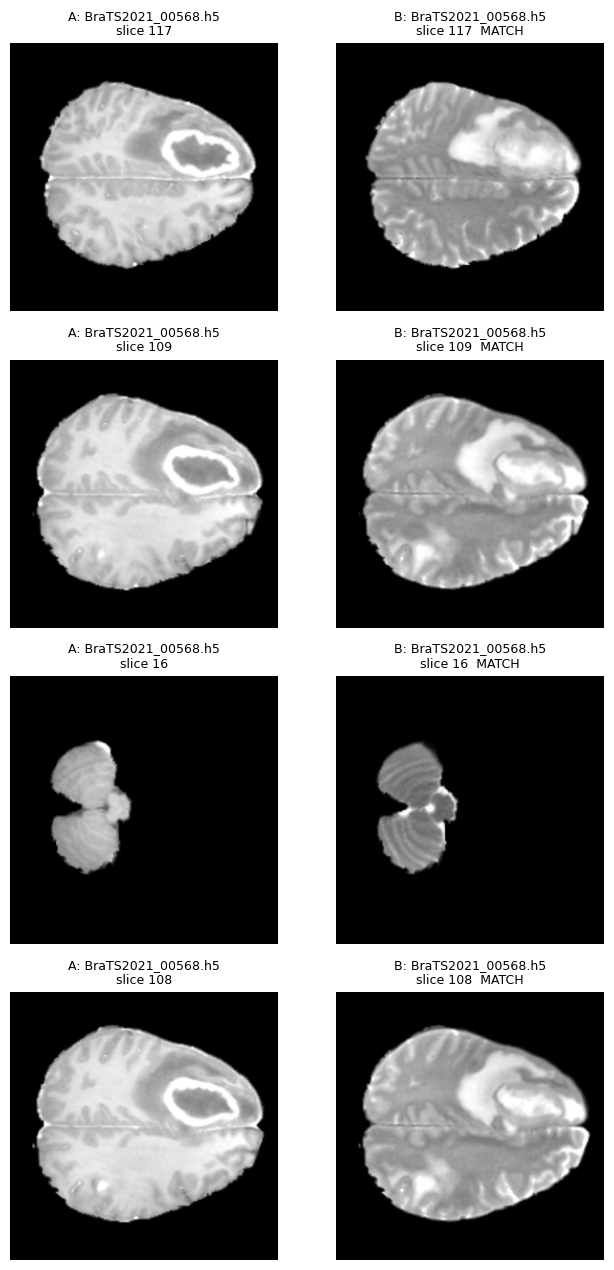

In [13]:
eval_check_dataset = PairingCheckDataset(
    h5_files=h5_files,
    modality_a=cfg.data.modality_a,
    modality_b=cfg.data.modality_b,
    augmentations=aug,
    # paired defaults to True — correct for eval
)
assert eval_check_dataset.paired is True

eval_check_loader = DataLoader(eval_check_dataset, batch_size=4, shuffle=True, num_workers=0)
batch = next(iter(eval_check_loader))
assert_batch_paired(batch)
show_paired_batch_with_labels(batch)

In [14]:
def scan_loader_for_pairing_bugs(loader, num_batches=20):
    bad_batches = 0
    it = iter(loader)
    for b_idx in range(num_batches):
        b = next(it)
        try:
            assert_batch_paired(b, verbose=False)
        except AssertionError as e:
            bad_batches += 1
            print(f"batch {b_idx}: {e}")
    print(f"\nScanned {num_batches} batches — {bad_batches} had mismatches")

scan_loader_for_pairing_bugs(eval_check_loader, num_batches=20)

✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired
✓ batch is correctly paired

Scanned 20 batches — 0 had mismatches


In [15]:
train_check_dataset = PairingCheckDataset(
    h5_files=h5_files,
    modality_a=cfg.data.modality_a,
    modality_b=cfg.data.modality_b,
    augmentations=aug,
    paired=False,   # mirrors get_h5_dataloaders.py's training call
)
train_check_loader = DataLoader(train_check_dataset, batch_size=4, shuffle=True, num_workers=0)
batch = next(iter(train_check_loader))

# Expect mismatches here — that's correct for unpaired training
try:
    assert_batch_paired(batch)
except AssertionError:
    print("✓ training loader is unpaired as intended (mismatches expected)")

[H5MRIDataset] Indexing 1 files ...
  BraTS2021_00568.h5: 136/182 slices indexed
[H5MRIDataset] Ready — 136 A-slices, 136 B-slices
[MISMATCH] idx=0  path_a=BraTS2021_00568.h5 slice_a=70  |  path_b=BraTS2021_00568.h5 slice_b=94
[MISMATCH] idx=1  path_a=BraTS2021_00568.h5 slice_a=67  |  path_b=BraTS2021_00568.h5 slice_b=63
[MISMATCH] idx=2  path_a=BraTS2021_00568.h5 slice_a=104  |  path_b=BraTS2021_00568.h5 slice_b=14
[MISMATCH] idx=3  path_a=BraTS2021_00568.h5 slice_a=51  |  path_b=BraTS2021_00568.h5 slice_b=145
✓ training loader is unpaired as intended (mismatches expected)


In [16]:
class PairingCheckPix2PixDataset(H5Pix2PixDataset):
    """
    Mirrors PairingCheckDataset but for H5Pix2PixDataset's label/images
    naming. Notebook-only.
    """
    def __getitem__(self, idx):
        base = self._base
        path_a, si_a = base.index_a[idx % len(base.index_a)]
        if base.paired:
            path_b, si_b = base.index_b[idx % len(base.index_b)]
        else:
            path_b, si_b = random.choice(base.index_b)

        item = base[idx]
        return {
            "label": item["images_a"], "images": item["images_b"],
            "path_a": str(path_a), "path_b": str(path_b),
            "slice_a": si_a, "slice_b": si_b,
        }

[H5MRIDataset] Indexing 1 files ...
  BraTS2021_00568.h5: 136/182 slices indexed
[H5MRIDataset] Ready — 136 A-slices, 136 B-slices
[OK ] idx=0  path_a=BraTS2021_00568.h5 slice_a=147  |  path_b=BraTS2021_00568.h5 slice_b=147
[OK ] idx=1  path_a=BraTS2021_00568.h5 slice_a=103  |  path_b=BraTS2021_00568.h5 slice_b=103
[OK ] idx=2  path_a=BraTS2021_00568.h5 slice_a=44  |  path_b=BraTS2021_00568.h5 slice_b=44
[OK ] idx=3  path_a=BraTS2021_00568.h5 slice_a=20  |  path_b=BraTS2021_00568.h5 slice_b=20
✓ batch is correctly paired


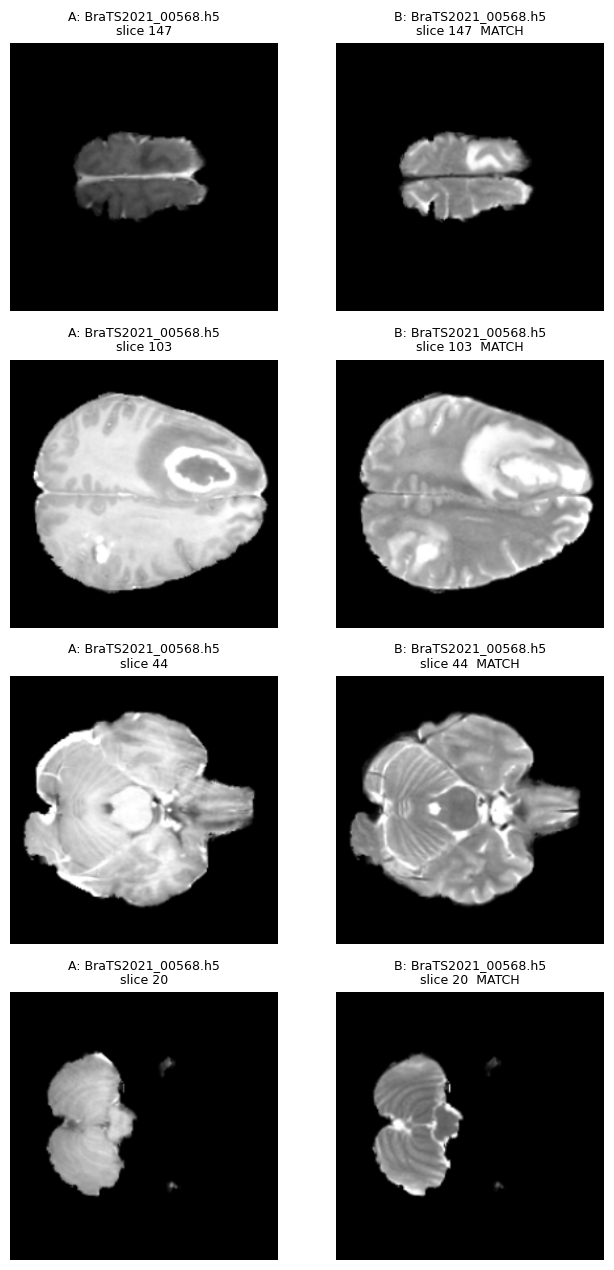

In [17]:
p2p_check_dataset = PairingCheckPix2PixDataset(
    h5_files=h5_files,
    modality_a=cfg.data.modality_a,
    modality_b=cfg.data.modality_b,
    augmentations=aug,
)
assert p2p_check_dataset._base.paired, (
    "PairingCheckPix2PixDataset built with paired=False — "
    "pix2pixHD requires paired=True to function correctly."
)

p2p_check_loader = DataLoader(p2p_check_dataset, batch_size=4, shuffle=True, num_workers=0)
batch = next(iter(p2p_check_loader))
assert_batch_paired(batch)
show_paired_batch_with_labels(batch, key_a="label", key_b="images")